Tamaño: (562, 632)
Valores encontrados: [  0 255]


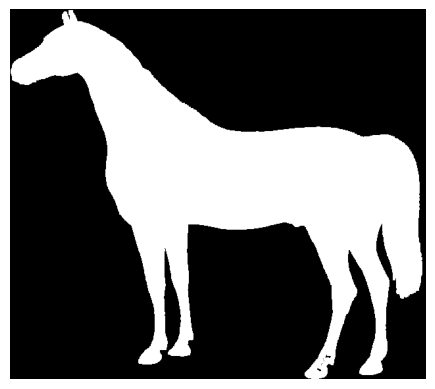

Inicio: (1, 89)
Angular Freeman Chain Code F8:
00000020070170107171070700000171700170017171717017171710070171717100717277171717172771710710727001700071007270170177100000170171717170717171702771171707207007277117000017710710001771071007100007117711770277000277010727702770027701727071000007171710000000701071070107017170170171700017000000170000000170000000000000000000007100170000000710000000000071000007100000007100000071000000071000000000000071000000000000000071000017000000000000001700000000170170001700170017017017002770107001070016100000007100710000000000710000000000017017017027070010071727701017710001077207720701710070107171000710071000710007100000000071000000000000000017710016100170071001771001700000000001700000000000000000000000000007100000701000000000000717100160100177100000000000000000001717000000001700170170002007072071710077277271001670200172007177002710017071000000000000076702002000000000071000710007107107107171070100071071071007100007100000071071001610000000000767171717017017001

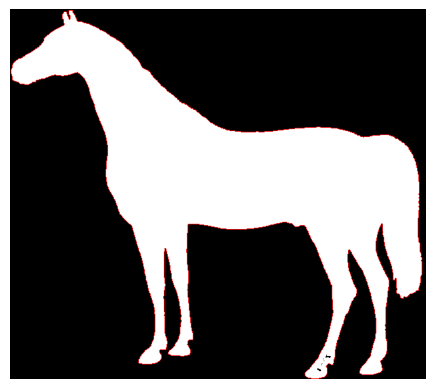

In [ ]:
import numpy as np
import cv2
from PIL import Image
import matplotlib.pyplot as plt

# 1. Cargar la imagen GIF
# Puedes cambiar 'ruta' por la ubicación de tu archivo .gif
ruta = input("Introduce la ruta del GIF: ")

imagen = Image.open(ruta)
imagen.seek(0)

# Convertimos el GIF a escala de grises
imagen = imagen.convert("L")

# Lo convertimos en matriz NumPy
matriz = np.array(imagen)

print("Tamaño:", matriz.shape)
print("Valores encontrados:", np.unique(matriz))

# 2. Mostrar la imagen original
plt.imshow(matriz, cmap="gray")
plt.axis("off")
plt.show()

# 3. Encontrar el píxel inicial (el primer píxel del objeto, valor 255)
def encontrar_inicio(imagen):
    alto, ancho = imagen.shape
    for y in range(alto):
        for x in range(ancho):
            if imagen[y, x] == 255:
                return y, x
    return None

inicio = encontrar_inicio(matriz)
print("Inicio:", inicio)

# Diccionario de direcciones para el código de Freeman de 8 direcciones (F8)
direcciones = {
    0: (0, 1),      # Derecha
    1: (1, 1),      # Abajo-derecha
    2: (1, 0),      # Abajo
    3: (1, -1),     # Abajo-izquierda
    4: (0, -1),     # Izquierda
    5: (-1, -1),    # Arriba-izquierda
    6: (-1, 0),     # Arriba
    7: (-1, 1)      # Arriba-derecha
}

def siguiente_pixel(imagen, actual, direccion_anterior):
    y, x = actual
    alto, ancho = imagen.shape

    # Orden de búsqueda en sentido horario basado en la dirección anterior
    orden = [
        (direccion_anterior + 6) % 8,
        (direccion_anterior + 7) % 8,
        direccion_anterior,
        (direccion_anterior + 1) % 8,
        (direccion_anterior + 2) % 8,
        (direccion_anterior + 3) % 8,
        (direccion_anterior + 4) % 8,
        (direccion_anterior + 5) % 8
    ]

    for direccion in orden:
        dy, dx = direcciones[direccion]
        nuevo_y = y + dy
        nuevo_x = x + dx

        # Comprobar límites
        if 0 <= nuevo_y < alto and 0 <= nuevo_x < ancho:
            # ¿Es parte del objeto?
            if imagen[nuevo_y, nuevo_x] == 255:
                return (nuevo_y, nuevo_x), direccion

    return None, None

def obtener_chain_code(imagen, inicio):
    actual = inicio
    direccion_anterior = 0  # Dirección inicial por defecto: derecha
    cadena = []
    recorrido = [inicio]

    alto, ancho = imagen.shape
    max_iteraciones = alto * ancho  # Límite de seguridad

    for _ in range(max_iteraciones):
        siguiente, direccion = siguiente_pixel(
            imagen,
            actual,
            direccion_anterior
        )

        if siguiente is None:
            print("No se encontró un siguiente píxel.")
            break

        cadena.append(direccion)
        recorrido.append(siguiente)

        actual = siguiente
        direccion_anterior = direccion

        # Regresamos al inicio cerrando el contorno
        if actual == inicio and len(cadena) > 1:
            break

    return cadena, recorrido

# Ejecutar la obtención del código de cadena
cadena, recorrido = obtener_chain_code(matriz, inicio)

# 4. Obtener e imprimir la cadena de texto resultante
cadena_string = ''.join(map(str, cadena))

print("Chain Code F8:")
print(cadena_string)
print("\nLongitud:", len(cadena_string))

# 5. Mostrar la ruta trazada sobre la imagen
imagen_recorrido = cv2.cvtColor(matriz, cv2.COLOR_GRAY2BGR)

for i in range(len(recorrido) - 1):
    y1, x1 = recorrido[i]
    y2, x2 = recorrido[i + 1]
    cv2.line(imagen_recorrido, (x1, y1), (x2, y2), (0, 0, 255), 1)

plt.imshow(cv2.cvtColor(imagen_recorrido, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()